In [1]:
# IMPORTANT: this must be the first code cell in a fresh kernel, before importing TensorFlow.
import os
GPU_ID = "3"  # physical GPU 3 on the DGX host; it will appear as /GPU:0 here
os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID

import glob
import random
import math
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from sklearn.model_selection import train_test_split

SEED = 42
IMG_SIZE = (256, 256)
BATCH_SIZE = 1
EPOCHS = 50
LEARNING_RATE = 1e-4
VALIDATION_SIZE = 0.20
BOUNDARY_TOLERANCE_PX = 2
PREDICTION_THRESHOLD = 0.5

IMAGE_DIR = "/raid/home/dgx1725/Our_data/Our_data/images"
MASK_DIR  = "/raid/home/dgx1725/Our_data/Our_data/masks"
OUTPUT_DIR = "/raid/home/dgx1725/resunet_our_data_longskip_outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)
for directory, label in [(IMAGE_DIR, "IMAGE_DIR"), (MASK_DIR, "MASK_DIR")]:
    if not os.path.isdir(directory):
        raise FileNotFoundError(f"{label} does not exist: {directory}")

print("Image directory:", IMAGE_DIR)
print("Binary-mask directory:", MASK_DIR)
print("Output directory:", OUTPUT_DIR)
print("Images found:", len([p for p in Path(IMAGE_DIR).iterdir() if p.is_file()]))
print("Masks found :", len([p for p in Path(MASK_DIR).iterdir() if p.is_file()]))
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Configure memory growth before any GPU operation initializes the device.
physical_gpus = tf.config.list_physical_devices("GPU")
print("Visible TensorFlow GPUs:", physical_gpus)
for gpu in physical_gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print("Could not set memory growth (GPU may already be initialized):", exc)

if physical_gpus:
    try:
        with tf.device("/GPU:0"):
            _a = tf.random.uniform((256, 256))
            _b = tf.random.uniform((256, 256))
            _test = tf.linalg.matmul(_a, _b)
            _ = _test.numpy()
        print("GPU matrix-operation test: PASS")
    except Exception as exc:
        raise RuntimeError(
            "GPU was detected, but the GPU matrix-operation test failed. "
            "Restart Jupyter from the DGX terminal using the LD_LIBRARY_PATH command in the first markdown cell, "
            "then restart this notebook kernel. Also check free memory with nvidia-smi."
        ) from exc
else:
    print("WARNING: TensorFlow sees no GPU; training will run on CPU unless the environment is fixed.")

print("TensorFlow version:", tf.__version__)

2026-10-16 15:05:22.312888: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-16 15:05:22.312932: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-16 15:05:22.314509: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-16 15:05:22.323432: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-16 15:05:23.288530: W tensorflow/compiler/tf2

Image directory: /raid/home/dgx1725/Our_data/Our_data/images
Binary-mask directory: /raid/home/dgx1725/Our_data/Our_data/masks
Output directory: /raid/home/dgx1725/resunet_our_data_longskip_outputs
Images found: 16
Masks found : 16
Visible TensorFlow GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


2026-10-16 15:05:26.681074: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1929] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 10707 MB memory:  -> device: 0, name: Tesla V100-SXM2-32GB, pci bus id: 0000:0b:00.0, compute capability: 7.0


GPU matrix-operation test: PASS
TensorFlow version: 2.15.1


Images found: 16
Masks found: 16
Matched pairs: 16
Unmatched images: 0
Unmatched masks: 0
Total pairs: 16 | Train: 12 | Validation: 4


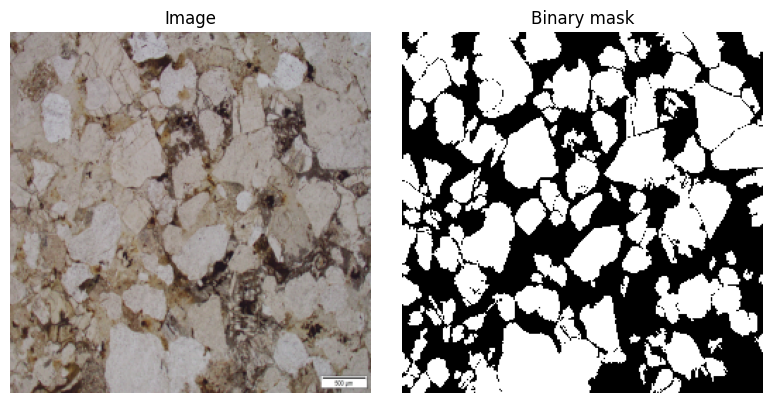

In [2]:
VALID_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

def list_image_files(directory):
    paths = []
    for ext in VALID_EXTENSIONS:
        paths.extend(glob.glob(os.path.join(directory, f"*{ext}")))
        paths.extend(glob.glob(os.path.join(directory, f"*{ext.upper()}")))
    # Deduplicate case-insensitive glob overlaps while retaining sorted order.
    return sorted(set(paths))

from pathlib import Path

def get_pairs(image_dir, mask_dir):
    image_dir = Path(image_dir)
    mask_dir = Path(mask_dir)

    image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
    mask_exts = {".png", ".tif", ".tiff", ".bmp"}

    image_files = sorted(
        p for p in image_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in image_exts
    )

    mask_files = sorted(
        p for p in mask_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in mask_exts
    )

    # Map image filenames without extensions
    image_map = {
        p.stem.lower(): p
        for p in image_files
    }

    # Normalize mask names by removing the trailing "_mask"
    mask_map = {}

    for p in mask_files:
        stem = p.stem.lower()

        if stem.endswith("_mask"):
            stem = stem[:-5]

        mask_map[stem] = p

    # Match using normalized names
    common_names = sorted(
        set(image_map.keys()) & set(mask_map.keys())
    )

    pairs = [
        (str(image_map[name]), str(mask_map[name]))
        for name in common_names
    ]

    unmatched_images = sorted(
        str(p) for p in image_files
        if p.stem.lower() not in mask_map
    )

    unmatched_masks = sorted(
        str(p) for p in mask_files
        if (p.stem.lower()[:-5]
            if p.stem.lower().endswith("_mask")
            else p.stem.lower()) not in image_map
    )

    print("Images found:", len(image_files))
    print("Masks found:", len(mask_files))
    print("Matched pairs:", len(pairs))
    print("Unmatched images:", len(unmatched_images))
    print("Unmatched masks:", len(unmatched_masks))

    if unmatched_images:
        print("Unmatched image examples:", unmatched_images[:5])

    if unmatched_masks:
        print("Unmatched mask examples:", unmatched_masks[:5])

    if not pairs:
        raise RuntimeError(
            "No image-mask pairs found. Check paths and filenames."
        )

    return pairs

def _path_string(path):
    if isinstance(path, (bytes, np.bytes_)):
        return path.decode("utf-8")
    if isinstance(path, np.ndarray) and path.dtype.kind in ("S", "U"):
        path = path.item()
        return path.decode("utf-8") if isinstance(path, bytes) else str(path)
    return os.fspath(path)

def load_image_mask(img_path, mask_path):
    img_path = _path_string(img_path)
    mask_path = _path_string(mask_path)

    image = cv2.imread(img_path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Could not read image: {img_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_AREA)
    image = image.astype(np.float32) / 255.0

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Could not read binary mask: {mask_path}")
    mask = cv2.resize(mask, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_NEAREST)
    mask = (mask > 127).astype(np.float32)
    mask = mask[..., np.newaxis]
    return image, mask

def tf_load_image_mask(img_path, mask_path):
    image, mask = tf.numpy_function(
        func=load_image_mask,
        inp=[img_path, mask_path],
        Tout=[tf.float32, tf.float32]
    )
    image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    mask.set_shape([IMG_SIZE[0], IMG_SIZE[1], 1])
    return image, mask

pairs = get_pairs(IMAGE_DIR, MASK_DIR)
train_pairs, val_pairs = train_test_split(
    pairs, test_size=VALIDATION_SIZE, random_state=SEED, shuffle=True
)
print(f"Total pairs: {len(pairs)} | Train: {len(train_pairs)} | Validation: {len(val_pairs)}")

AUTOTUNE = tf.data.AUTOTUNE

def augment(image, mask):
    # Same random transform is applied to both tensors.
    if tf.random.uniform(()) > 0.5:
        image, mask = tf.image.flip_left_right(image), tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        image, mask = tf.image.flip_up_down(image), tf.image.flip_up_down(mask)
    return image, mask

def make_dataset(sample_pairs, training=False):
    image_paths = [p[0] for p in sample_pairs]
    mask_paths = [p[1] for p in sample_pairs]
    ds = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))
    if training:
        ds = ds.shuffle(buffer_size=max(1, len(sample_pairs)), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(tf_load_image_mask, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_pairs, training=True)
val_ds = make_dataset(val_pairs, training=False)

# Visual sanity check on one paired example.
_check_img, _check_mask = load_image_mask(train_pairs[0][0], train_pairs[0][1])
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(_check_img); axes[0].set_title("Image")
axes[1].imshow(_check_mask[..., 0], cmap="gray"); axes[1].set_title("Binary mask")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

In [3]:
def residual_block_initial(x, filters, strides=(1, 1), name="res_initial"):
    """First residual block: Conv-BN-ReLU-Conv plus a projected shortcut."""
    y = tf.keras.layers.Conv2D(
        filters, 3, strides=strides[0], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_conv1"
    )(x)
    y = tf.keras.layers.BatchNormalization(name=f"{name}_bn1")(y)
    y = tf.keras.layers.Activation("relu", name=f"{name}_relu1")(y)
    y = tf.keras.layers.Conv2D(
        filters, 3, strides=strides[1], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_conv2"
    )(y)
    shortcut = tf.keras.layers.Conv2D(
        filters, 1, strides=strides[0], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_shortcut_conv"
    )(x)
    shortcut = tf.keras.layers.BatchNormalization(name=f"{name}_shortcut_bn")(shortcut)
    return tf.keras.layers.Add(name=f"{name}_add")([shortcut, y])


def residual_block(x, filters, strides=(1, 1), name="res_block"):
    """Pre-activation residual block with projection when shape/channels differ."""
    input_channels = x.shape[-1]
    y = tf.keras.layers.BatchNormalization(name=f"{name}_bn1")(x)
    y = tf.keras.layers.Activation("relu", name=f"{name}_relu1")(y)
    y = tf.keras.layers.Conv2D(
        filters, 3, strides=strides[0], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_conv1"
    )(y)
    y = tf.keras.layers.BatchNormalization(name=f"{name}_bn2")(y)
    y = tf.keras.layers.Activation("relu", name=f"{name}_relu2")(y)
    y = tf.keras.layers.Conv2D(
        filters, 3, strides=strides[1], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_conv2"
    )(y)

    if strides[0] != 1 or input_channels != filters:
        shortcut = tf.keras.layers.Conv2D(
            filters, 1, strides=strides[0], padding="same", use_bias=False,
            kernel_initializer="he_normal", name=f"{name}_shortcut_conv"
        )(x)
        shortcut = tf.keras.layers.BatchNormalization(name=f"{name}_shortcut_bn")(shortcut)
    else:
        shortcut = x
    return tf.keras.layers.Add(name=f"{name}_add")([shortcut, y])


def project_and_resize(feature, target_tensor, filters, name):
    """Project a skip with 1x1 Conv-BN-ReLU, then resize to decoder HxW."""
    feature = tf.keras.layers.Conv2D(
        filters, kernel_size=1, padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_project_conv"
    )(feature)
    feature = tf.keras.layers.BatchNormalization(name=f"{name}_project_bn")(feature)
    feature = tf.keras.layers.Activation("relu", name=f"{name}_project_relu")(feature)

    target_h, target_w = target_tensor.shape[1], target_tensor.shape[2]
    if target_h is None or target_w is None:
        raise ValueError(f"Static decoder spatial dimensions are required for {name}.")
    feature = tf.keras.layers.Resizing(
        int(target_h), int(target_w), interpolation="bilinear", name=f"{name}_resize"
    )(feature)
    return feature


def multi_skip_decoder_block(x, skip_features, filters, name):
    """Upsample decoder features, align all encoder skips, concatenate, then residual block."""
    x = tf.keras.layers.UpSampling2D(
        size=(2, 2), interpolation="bilinear", name=f"{name}_upsample"
    )(x)

    projected_skips = [
        project_and_resize(skip, x, filters, name=f"{name}_skip{i+1}")
        for i, skip in enumerate(skip_features)
    ]
    x = tf.keras.layers.Concatenate(name=f"{name}_concat")([x] + projected_skips)
    x = residual_block(x, filters, name=f"{name}_residual")
    return x


def build_resunet_long_multiskip(input_shape=(256, 256, 3), filters=(64, 128, 256, 512)):
    """ResUNet with Modification 1 long multi-skip connections only."""
    inputs = tf.keras.Input(shape=input_shape, name="image")

    # Encoder feature maps: e0=256x256, e1=128x128, e2=64x64, e3=32x32.
    e0 = residual_block_initial(inputs, filters[0], name="encoder_block0")
    e1 = residual_block(e0, filters[1], strides=(2, 1), name="encoder_block1")
    e2 = residual_block(e1, filters[2], strides=(2, 1), name="encoder_block2")
    e3 = residual_block(e2, filters[3], strides=(2, 1), name="encoder_block3")

    # Bridge: 32x32 -> 16x16, with twice the deepest encoder filters.
    bridge = residual_block(e3, filters[3] * 2, strides=(2, 1), name="bridge")

    # Modification 1 mapping, matching the long multi-skip U-Net variant:
    # d3 <- [e3], d2 <- [e2, e3], d1 <- [e1, e2], d0 <- [e0, e1].
    d3 = multi_skip_decoder_block(bridge, [e3], filters[3], name="decoder_block3")
    d2 = multi_skip_decoder_block(d3, [e2, e3], filters[2], name="decoder_block2")
    d1 = multi_skip_decoder_block(d2, [e1, e2], filters[1], name="decoder_block1")
    d0 = multi_skip_decoder_block(d1, [e0, e1], filters[0], name="decoder_block0")

    logits = tf.keras.layers.Conv2D(
        1, kernel_size=1, padding="same", activation=None, name="segmentation_logits"
    )(d0)
    return tf.keras.Model(inputs=inputs, outputs=logits, name="ResUNet_LongMultiSkip_Mod1")


# Metrics used during training receive logits and threshold at logit 0 (= probability 0.5).
def _binary_from_logits(y_true, y_pred):
    y_true = tf.cast(y_true >= 0.5, tf.float32)
    y_pred = tf.cast(y_pred >= 0.0, tf.float32)
    return y_true, y_pred


def binary_accuracy_logits(y_true, y_pred):
    y_true, y_pred = _binary_from_logits(y_true, y_pred)
    return tf.reduce_mean(tf.cast(tf.equal(y_true, y_pred), tf.float32))


def dice_coef_logits(y_true, y_pred, smooth=1e-7):
    y_true, y_pred = _binary_from_logits(y_true, y_pred)
    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true * y_pred)
    return (2.0 * intersection + smooth) / (
        tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth
    )


def iou_coef_logits(y_true, y_pred, smooth=1e-7):
    y_true, y_pred = _binary_from_logits(y_true, y_pred)
    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)


PAPER_FILTERS = (64, 128, 256, 512)
model = build_resunet_long_multiskip(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    filters=PAPER_FILTERS
)
print("Encoder filters:", PAPER_FILTERS)
print("Bridge filters:", PAPER_FILTERS[-1] * 2)
print("Long multi-skip mapping: d3 <- [e3], d2 <- [e2, e3], d1 <- [e1, e2], d0 <- [e0, e1]")
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[binary_accuracy_logits, dice_coef_logits, iou_coef_logits]
)
model.summary()


Encoder filters: (64, 128, 256, 512)
Bridge filters: 1024
Long multi-skip mapping: d3 <- [e3], d2 <- [e2, e3], d1 <- [e1, e2], d0 <- [e0, e1]
Model: "ResUNet_LongMultiSkip_Mod1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 image (InputLayer)          [(None, 256, 256, 3)]        0         []                            
                                                                                                  
 encoder_block0_conv1 (Conv  (None, 256, 256, 64)         1728      ['image[0][0]']               
 2D)                                                                                              
                                                                                                  
 encoder_block0_bn1 (BatchN  (None, 256, 256, 64)         256       ['encoder_block0_conv1[0][0]']
 ormalization)                

In [4]:
BEST_WEIGHTS_PATH = os.path.join(OUTPUT_DIR, "best_resunet_long_multiskip_mod1.weights.h5")

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=BEST_WEIGHTS_PATH,
        monitor="val_dice_coef_logits",
        mode="max",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice_coef_logits",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_dice_coef_logits",
        mode="max",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

history_df = pd.DataFrame(history.history)
history_csv = os.path.join(OUTPUT_DIR, "training_history.csv")
history_df.to_csv(history_csv, index_label="epoch")
print("Training history saved:", history_csv)

# Save the trained model. For inference-only reload, use load_model(..., compile=False).
FINAL_MODEL_PATH = os.path.join(OUTPUT_DIR, "resunet_long_multiskip_mod1_final.keras")
model.save(FINAL_MODEL_PATH)
print("Saved trained model:", FINAL_MODEL_PATH)
print("Saved best weights:", BEST_WEIGHTS_PATH)

Epoch 1/50


2026-10-16 15:06:00.478886: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2026-10-16 15:06:07.687771: W external/local_tsl/tsl/framework/bfc_allocator.cc:366] Garbage collection: deallocate free memory regions (i.e., allocations) so that we can re-allocate a larger region to avoid OOM due to memory fragmentation. If you see this message frequently, you are running near the threshold of the available device memory and re-allocation may incur great performance overhead. You may try smaller batch sizes to observe the performance impact. Set TF_ENABLE_GPU_GARBAGE_COLLECTION=false if you'd like to disable this feature.
2026-10-16 15:06:12.020539: I external/local_xla/xla/service/service.cc:168] XLA service 0x7f3ae4a48b10 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-16 15:06:12.020588: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): Tesla V100-SXM2-32GB, Compute Capabil

12/12 [==============================] - ETA: 0s - loss: 0.7230 - binary_accuracy_logits: 0.6919 - dice_coef_logits: 0.7623 - iou_coef_logits: 0.6198
Epoch 1: val_dice_coef_logits improved from -inf to 0.00001, saving model to /raid/home/dgx1725/resunet_our_data_longskip_outputs/best_resunet_long_multiskip_mod1.weights.h5
12/12 [==============================] - 43s 302ms/step - loss: 0.7230 - binary_accuracy_logits: 0.6919 - dice_coef_logits: 0.7623 - iou_coef_logits: 0.6198 - val_loss: 34.0135 - val_binary_accuracy_logits: 0.4376 - val_dice_coef_logits: 1.2074e-05 - val_iou_coef_logits: 6.0373e-06 - lr: 1.0000e-04
Epoch 2/50
12/12 [==============================] - ETA: 0s - loss: 0.4974 - binary_accuracy_logits: 0.7726 - dice_coef_logits: 0.8276 - iou_coef_logits: 0.7077
Epoch 2: val_dice_coef_logits improved from 0.00001 to 0.71404, saving model to /raid/home/dgx1725/resunet_our_data_longskip_outputs/best_resunet_long_multiskip_mod1.weights.h5
12/12 [==============================]

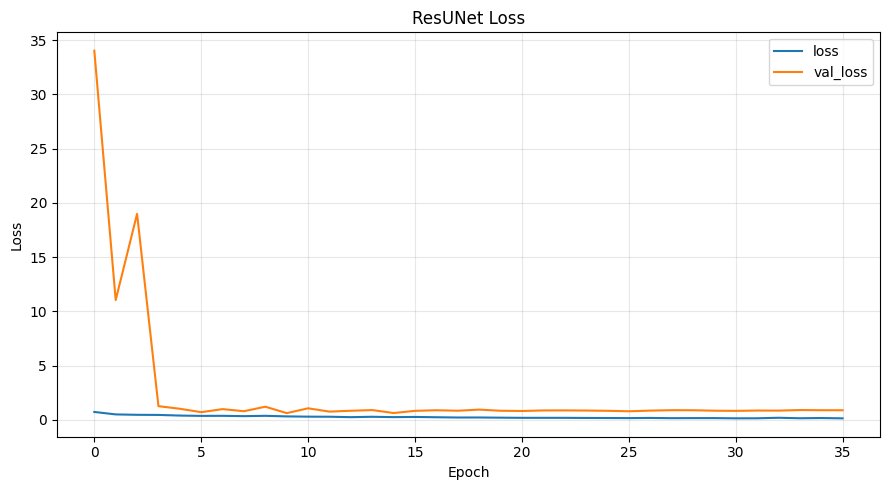

Saved: /raid/home/dgx1725/resunet_our_data_longskip_outputs/training_loss.png


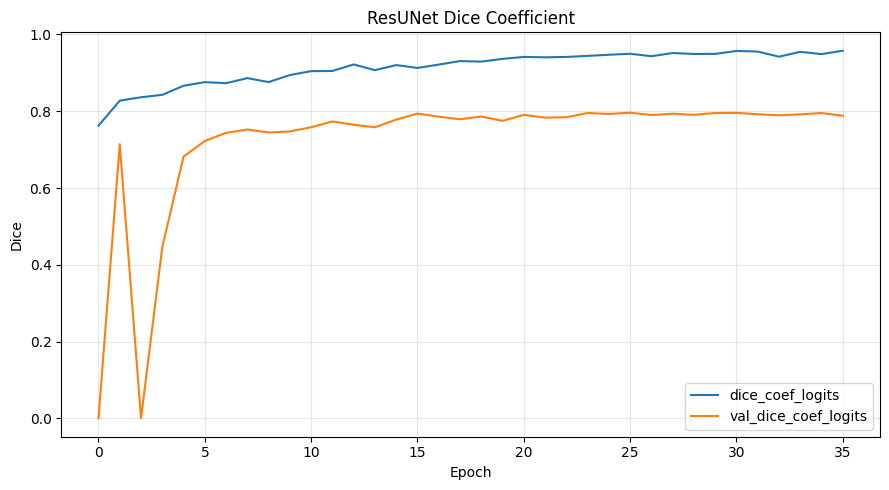

Saved: /raid/home/dgx1725/resunet_our_data_longskip_outputs/training_dice.png


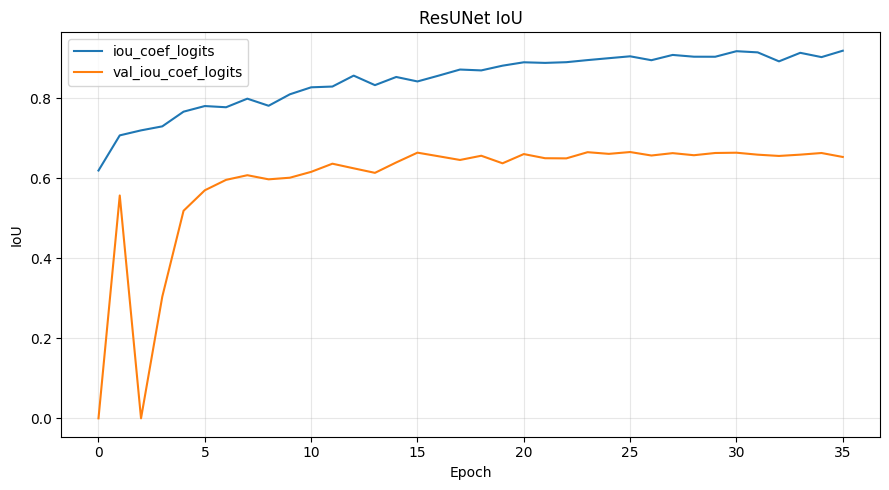

Saved: /raid/home/dgx1725/resunet_our_data_longskip_outputs/training_iou.png
Evaluation ground-truth source: /raid/home/dgx1725/Our_data/Our_data/masks


In [5]:
def plot_history(history_dict, keys, title, ylabel, output_name):
    plt.figure(figsize=(9, 5))
    plotted = False
    for key in keys:
        if key in history_dict:
            plt.plot(history_dict[key], label=key)
            plotted = True
    if not plotted:
        print("No matching history keys for:", keys)
        plt.close()
        return
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    path = os.path.join(OUTPUT_DIR, output_name)
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    print("Saved:", path)

plot_history(history.history, ["loss", "val_loss"], "ResUNet Loss", "Loss", "training_loss.png")
plot_history(history.history, ["dice_coef_logits", "val_dice_coef_logits"], "ResUNet Dice Coefficient", "Dice", "training_dice.png")
plot_history(history.history, ["iou_coef_logits", "val_iou_coef_logits"], "ResUNet IoU", "IoU", "training_iou.png")

METRIC_COLUMNS = [
    "IoU", "Recall", "Precision", "Dice_Coefficient",
    "Boundary_F1", "Boundary_Recall", "Boundary_Precision"
]

def safe_divide(numerator, denominator):
    return float(numerator / denominator) if denominator else 0.0

def binary_segmentation_metrics(y_true, y_pred):
    """Seven pixel/boundary metrics for one boolean mask pair."""
    gt = np.asarray(y_true, dtype=bool)
    pred = np.asarray(y_pred, dtype=bool)

    tp = int(np.logical_and(gt, pred).sum())
    fp = int(np.logical_and(~gt, pred).sum())
    fn = int(np.logical_and(gt, ~pred).sum())
    union = tp + fp + fn

    precision = safe_divide(tp, tp + fp)
    recall = safe_divide(tp, tp + fn)
    iou = safe_divide(tp, union)
    dice = safe_divide(2 * tp, 2 * tp + fp + fn)

    # Derive 1-pixel contours from binary masks using morphology.
    gt_u8 = gt.astype(np.uint8)
    pred_u8 = pred.astype(np.uint8)
    erode_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    gt_eroded = cv2.erode(gt_u8, erode_kernel, iterations=1)
    pred_eroded = cv2.erode(pred_u8, erode_kernel, iterations=1)
    gt_boundary = (gt_u8 - gt_eroded).astype(bool)
    pred_boundary = (pred_u8 - pred_eroded).astype(bool)

    # A 5x5 elliptical kernel gives approximately 2-pixel matching tolerance.
    k = 2 * BOUNDARY_TOLERANCE_PX + 1
    tolerance_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    gt_boundary_dilated = cv2.dilate(gt_boundary.astype(np.uint8), tolerance_kernel, iterations=1).astype(bool)
    pred_boundary_dilated = cv2.dilate(pred_boundary.astype(np.uint8), tolerance_kernel, iterations=1).astype(bool)

    matched_pred_boundary = int(np.logical_and(pred_boundary, gt_boundary_dilated).sum())
    matched_gt_boundary = int(np.logical_and(gt_boundary, pred_boundary_dilated).sum())
    boundary_precision = safe_divide(matched_pred_boundary, int(pred_boundary.sum()))
    boundary_recall = safe_divide(matched_gt_boundary, int(gt_boundary.sum()))
    boundary_f1 = safe_divide(2 * boundary_precision * boundary_recall,
                              boundary_precision + boundary_recall)

    return {
        "IoU": iou,
        "Recall": recall,
        "Precision": precision,
        "Dice_Coefficient": dice,
        "Boundary_F1": boundary_f1,
        "Boundary_Recall": boundary_recall,
        "Boundary_Precision": boundary_precision,
    }

# Make sure the evaluation is not accidentally using another boundary-mask folder.
print("Evaluation ground-truth source:", MASK_DIR)
assert "Boundary_Mask_GT" not in MASK_DIR

[001/004] image1.jpg | IoU=0.7193 | Recall=0.8035 | Precision=0.8728 | Dice_Coefficient=0.8368 | Boundary_F1=0.8112 | Boundary_Recall=0.7994 | Boundary_Precision=0.8233
[002/004] image10.jpg | IoU=0.5967 | Recall=0.9926 | Precision=0.5994 | Dice_Coefficient=0.7475 | Boundary_F1=0.2297 | Boundary_Recall=0.1357 | Boundary_Precision=0.7464
[003/004] image14.png | IoU=0.7822 | Recall=0.9092 | Precision=0.8485 | Dice_Coefficient=0.8778 | Boundary_F1=0.8137 | Boundary_Recall=0.9522 | Boundary_Precision=0.7103
[004/004] image8.jpg | IoU=0.5660 | Recall=0.9301 | Precision=0.5911 | Dice_Coefficient=0.7228 | Boundary_F1=0.5050 | Boundary_Recall=0.6194 | Boundary_Precision=0.4262

=== Macro-average validation metrics (mean of per-image scores) ===
IoU                   : 0.6661
Recall                : 0.9088
Precision             : 0.7280
Dice_Coefficient      : 0.7962
Boundary_F1           : 0.5899
Boundary_Recall       : 0.6267
Boundary_Precision    : 0.6766

Per-image CSV: /raid/home/dgx1725/r

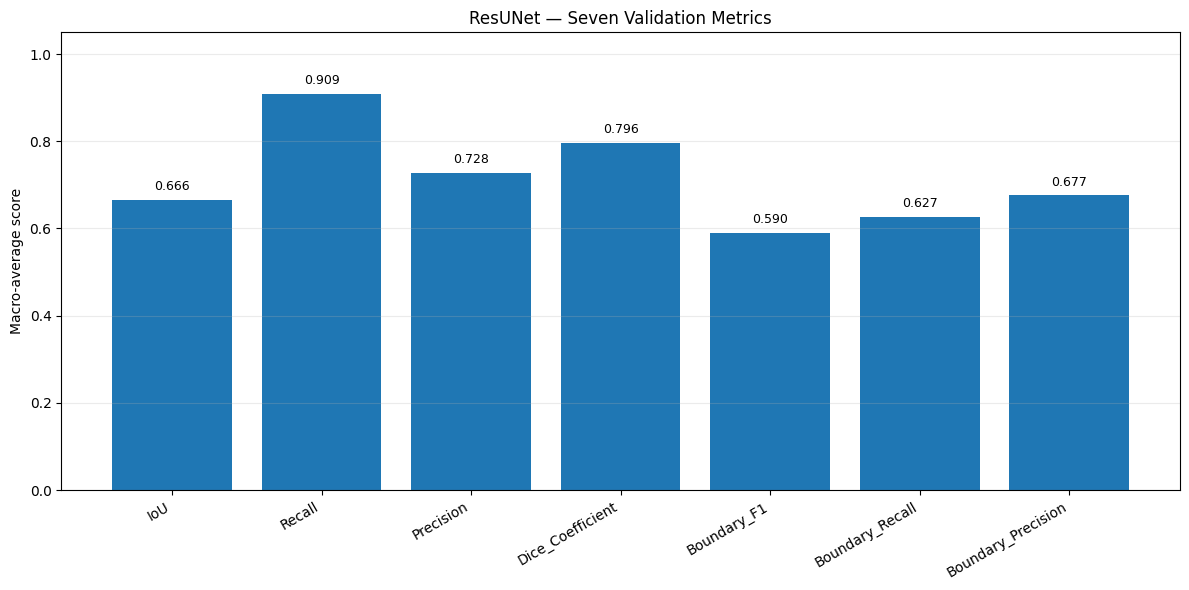

Saved: /raid/home/dgx1725/resunet_our_data_longskip_outputs/summary_metrics_bar.png


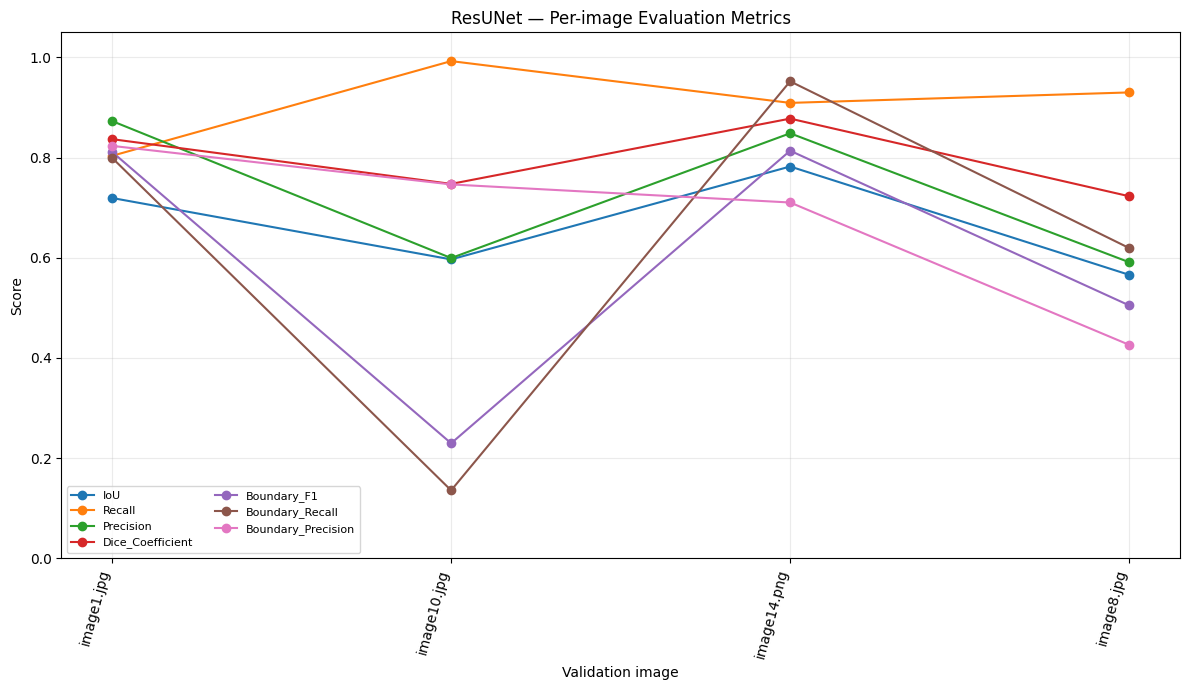

Saved: /raid/home/dgx1725/resunet_our_data_longskip_outputs/per_image_metrics.png


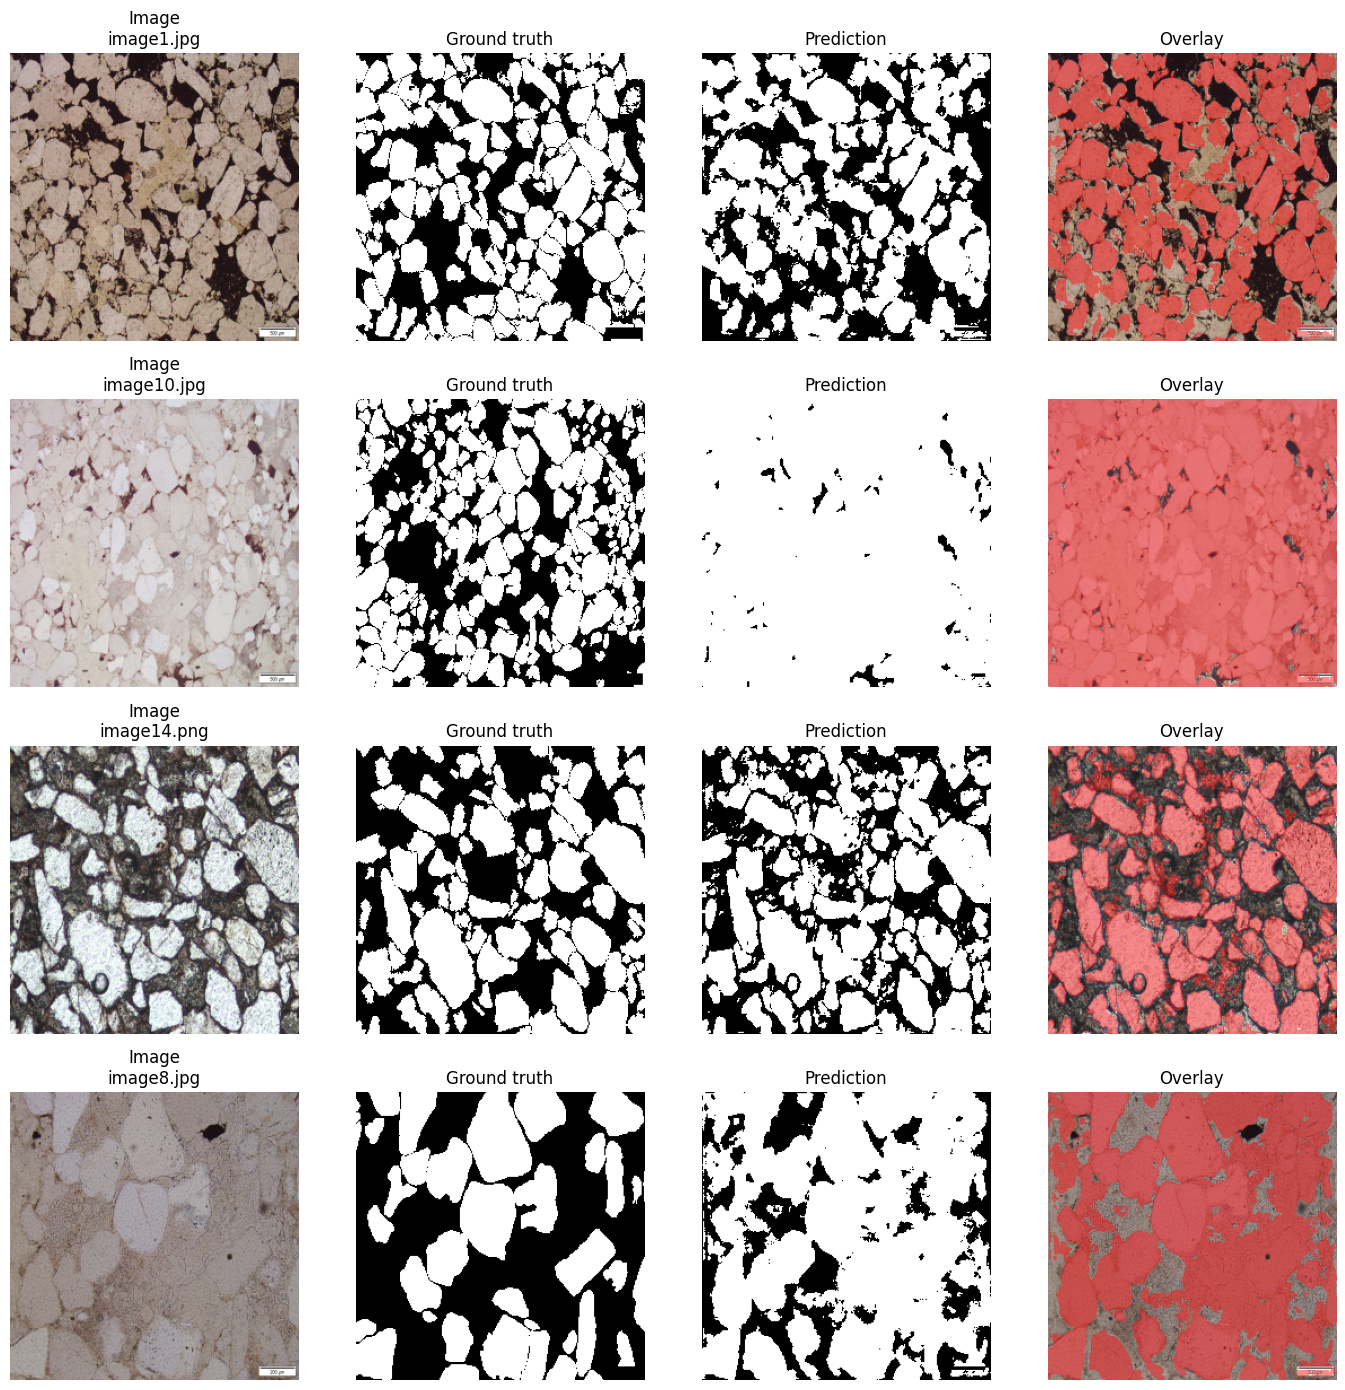

In [6]:
PREDICTION_DIR = os.path.join(OUTPUT_DIR, "predicted_masks")
PREVIEW_DIR = os.path.join(OUTPUT_DIR, "prediction_previews")
os.makedirs(PREDICTION_DIR, exist_ok=True)
os.makedirs(PREVIEW_DIR, exist_ok=True)

per_image_rows = []
preview_items = []

for idx, (image_path, mask_path) in enumerate(val_pairs, start=1):
    image, gt_mask = load_image_mask(image_path, mask_path)
    logits = model.predict(image[np.newaxis, ...], verbose=0)[0, ..., 0]
    probabilities = tf.math.sigmoid(logits).numpy()
    pred_mask = probabilities >= PREDICTION_THRESHOLD
    gt_binary = gt_mask[..., 0] >= 0.5

    metrics = binary_segmentation_metrics(gt_binary, pred_mask)
    row = {"image_name": Path(image_path).name, **metrics}
    per_image_rows.append(row)

    stem = Path(image_path).stem
    pred_u8 = (pred_mask.astype(np.uint8) * 255)
    cv2.imwrite(os.path.join(PREDICTION_DIR, f"{stem}_prediction.png"), pred_u8)

    # Save a visual comparison image: RGB original, GT, prediction, overlay.
    overlay = image.copy()
    overlay[pred_mask] = 0.55 * overlay[pred_mask] + 0.45 * np.array([1.0, 0.0, 0.0])
    if len(preview_items) < 8:
        preview_items.append((Path(image_path).name, image, gt_binary, pred_mask, overlay))

    preview_path = os.path.join(PREVIEW_DIR, f"{stem}_comparison.png")
    fig, axes = plt.subplots(1, 4, figsize=(14, 4))
    axes[0].imshow(image); axes[0].set_title("Image")
    axes[1].imshow(gt_binary, cmap="gray"); axes[1].set_title("Ground truth")
    axes[2].imshow(pred_mask, cmap="gray"); axes[2].set_title("Prediction")
    axes[3].imshow(np.clip(overlay, 0, 1)); axes[3].set_title("Prediction overlay")
    for ax in axes: ax.axis("off")
    fig.suptitle(Path(image_path).name)
    plt.tight_layout()
    fig.savefig(preview_path, dpi=140, bbox_inches="tight")
    plt.close(fig)

    print(
        f"[{idx:03d}/{len(val_pairs):03d}] {Path(image_path).name} | "
        + " | ".join(f"{name}={metrics[name]:.4f}" for name in METRIC_COLUMNS)
    )

if not per_image_rows:
    raise RuntimeError("Validation split is empty; increase the dataset size or adjust VALIDATION_SIZE.")

per_image_df = pd.DataFrame(per_image_rows)
per_image_csv = os.path.join(OUTPUT_DIR, "per_image_metrics.csv")
per_image_df.to_csv(per_image_csv, index=False)

summary_df = pd.DataFrame([{"metric": col, "macro_average": float(per_image_df[col].mean())} for col in METRIC_COLUMNS])
summary_csv = os.path.join(OUTPUT_DIR, "summary_metrics.csv")
summary_df.to_csv(summary_csv, index=False)

print("\n=== Macro-average validation metrics (mean of per-image scores) ===")
for _, row in summary_df.iterrows():
    print(f"{row['metric']:<22}: {row['macro_average']:.4f}")
print("\nPer-image CSV:", per_image_csv)
print("Summary CSV :", summary_csv)
print("Predicted masks:", PREDICTION_DIR)
print("Prediction comparison plots:", PREVIEW_DIR)
plt.figure(figsize=(12, 6))
bar_values = summary_df["macro_average"].to_numpy(dtype=float)
bars = plt.bar(summary_df["metric"], bar_values)
plt.ylim(0, 1.05)
plt.ylabel("Macro-average score")
plt.title("ResUNet — Seven Validation Metrics")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.25)
for bar, val in zip(bars, bar_values):
    plt.text(bar.get_x() + bar.get_width() / 2, val + 0.015, f"{val:.3f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
bar_plot_path = os.path.join(OUTPUT_DIR, "summary_metrics_bar.png")
plt.savefig(bar_plot_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", bar_plot_path)

plt.figure(figsize=(max(12, len(per_image_df) * 0.45), 7))
for metric in METRIC_COLUMNS:
    plt.plot(per_image_df["image_name"], per_image_df[metric], marker="o", linewidth=1.5, label=metric)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.xlabel("Validation image")
plt.title("ResUNet — Per-image Evaluation Metrics")
plt.xticks(rotation=75, ha="right")
plt.grid(True, alpha=0.25)
plt.legend(ncol=2, fontsize=8)
plt.tight_layout()
per_image_plot_path = os.path.join(OUTPUT_DIR, "per_image_metrics.png")
plt.savefig(per_image_plot_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", per_image_plot_path)
n_show = min(4, len(preview_items))
if n_show:
    fig, axes = plt.subplots(n_show, 4, figsize=(14, 3.5 * n_show))
    if n_show == 1:
        axes = np.expand_dims(axes, axis=0)
    for i, (name, image, gt, pred, overlay) in enumerate(preview_items[:n_show]):
        axes[i, 0].imshow(image); axes[i, 0].set_title(f"Image\n{name}")
        axes[i, 1].imshow(gt, cmap="gray"); axes[i, 1].set_title("Ground truth")
        axes[i, 2].imshow(pred, cmap="gray"); axes[i, 2].set_title("Prediction")
        axes[i, 3].imshow(np.clip(overlay, 0, 1)); axes[i, 3].set_title("Overlay")
        for ax in axes[i]: ax.axis("off")
    plt.tight_layout()
    plt.show()

In [ ]:
# Save predicted masks
PREDICTION_DIR = os.path.join(OUTPUT_DIR, "predicted_masks")
os.makedirs(PREDICTION_DIR, exist_ok=True)

for idx, (image_path, mask_path) in enumerate(val_pairs, start=1):
    image, _ = load_image_mask(image_path, mask_path)

    # Generate prediction
    logits = model.predict(image[np.newaxis, ...], verbose=0)[0, ..., 0]
    probabilities = tf.math.sigmoid(logits).numpy()
    pred_mask = probabilities >= PREDICTION_THRESHOLD

    # Convert mask to a black-and-white PNG (0 or 255)
    pred_mask_uint8 = (pred_mask.astype(np.uint8) * 255)

    # Save predicted mask
    filename = f"{Path(image_path).stem}_prediction.png"
    save_path = os.path.join(PREDICTION_DIR, filename)

    if not cv2.imwrite(save_path, pred_mask_uint8):
        raise IOError(f"Failed to save predicted mask: {save_path}")

    print(f"[{idx}/{len(val_pairs)}] Saved: {save_path}")

print(f"\nAll predicted masks saved in:\n{PREDICTION_DIR}")